# SoLEXS + HEL1OS joint spectral fit of one time bin (Aditya-L1)

| | |
|---|---|
| **Author** | Prakhar Singh |
| **Affiliation** | Aryabhatta Research Institute of Observational Sciences (ARIES), Nainital |
| **Email** | prakhar.aries@gmail.com |
| **Date** | 19 November 2026 |

---

Fits **one 20 s bin** of the non-thermal phase of the solar flare of 15 June 2025 with **SoLEXS** (SDD2, 2.8–15 keV)
and **HEL1OS** (CdTe1, 10–50 keV) together. At this time the spectrum has a hot thermal part (best seen by SoLEXS)
and a non-thermal tail (best seen by HEL1OS), so the two spectra are fitted jointly with one model.

**Model:** `constant * (chisoth + bknpower + chisoth_pre)`

| Component | Describes | Free parameters |
|---|---|---|
| `chisoth` | flare plasma (isothermal) | *T*, *EM*, Ar, Ca, Fe (Ni tied to Fe) |
| `bknpower` | non-thermal emission | &gamma; (above the break), *E*<sub>b</sub>, norm; index 1.5 below the break |
| `chisoth_pre` | pre-flare Sun (SoLEXS) | none: fitted on the pre-flare spectrum, then frozen |
| `constant` | cross-calibration | *C* for HEL1OS (1 for SoLEXS) |

Pre-flare emission: **modelled** for SoLEXS, **subtracted** for HEL1OS.

**Input:** the spectra made by notebook 1 (`outputs/spectra/<DAY>/`): **run notebook 1 first.**

**Output** (`outputs/joint_fit/`): MCMC chain, figure and XSPEC model (`.xcm`).

## 1. Settings
`BIN` must be one of the time bins of notebook 1. chspec is found through the environment variable `CHSPEC_DIR`
(or edit that line).

| Setting | Meaning |
|---|---|
| `BIN` | time bin to fit (UTC on `DAY`) |
| `SLX_RATE_MIN`, `SLX_WIDTH_MAX` | SoLEXS fit range ends at the first group below this rate or wider than this |
| `HLS_SNR_MIN` | HEL1OS fit range ends at the first group with net counts below this many σ |
| `SYSTEMATIC` | systematic error added to the model |

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from astropy.io import fits
import xspec as xs
%matplotlib inline

ROOT = Path.cwd().resolve().parent    # the repository folder (this notebook is in ROOT/notebooks/)
DAY  = '2025-06-15'
SPEC = ROOT / 'outputs' / 'spectra' / DAY      # spectra made by notebook 1
OUT  = ROOT / 'outputs' / 'joint_fit'          # MCMC chain, figure and XSPEC model are written here
CHSPEC_DIR = Path(os.environ.get('CHSPEC_DIR', '~/chspec')).expanduser()          # chspec (chisoth model)

# ---- the time bin to fit (non-thermal phase)
BIN = ('17:58:40', '17:59:00')

# ---- fit settings
SLX_RATE_MIN  = 1.0     # counts/s/keV  } SoLEXS: the fit range ends at the first group below this rate
SLX_WIDTH_MAX = 1.0     # keV           }         or wider than this
HLS_SNR_MIN   = 3.0     # HEL1OS: the fit range ends at the first group with net counts below this many sigma
SYSTEMATIC    = 0.05    # 5 % model systematic

# ---- level-1 data (unpacked by notebook 1; used for the light curves) and response files
SLX_PI      = ROOT / 'data/AL1_SLX_L1_20250615_v1.0/SDD2/AL1_SOLEXS_20250615_SDD2_L1.pi.gz'
SLX_GTI     = ROOT / 'data/AL1_SLX_L1_20250615_v1.0/SDD2/AL1_SOLEXS_20250615_SDD2_L1.gti.gz'
HLS_EVT     = ROOT / 'data/2025/06/15/HLS_20250615_121027_42565sec_lev1_V111/events/evt.fits'
SLX_EBOUNDS = ROOT / 'resources/solexs_caldb/ebounds/energy_bins_out_SDD2_v1.dat'
HLS_RMF     = ROOT / 'resources/hel1os_responses/hel1os_cdte_srf_v04.fits'
HLS_ARF     = ROOT / 'resources/hel1os_responses/hel1os_cdte_arf_v03.fits'

# ---- the spectra of BIN, from notebook 1
assert (SPEC / 'spectra_list.csv').exists(), f'{SPEC.relative_to(ROOT)} not found: run notebook 1 first'
bins = pd.read_csv(SPEC / 'spectra_list.csv', dtype=str).dropna()
row = bins[(bins.start == BIN[0]) & (bins.stop == BIN[1])]
assert len(row) == 1, f'{BIN} is not a bin of notebook 1: see {(SPEC / "spectra_list.csv").relative_to(ROOT)}'
SLX_FILE = row.slx_file.iloc[0]                             # SoLEXS spectrum of the bin
HLS_FILE = row.hls_file.iloc[0]                             # HEL1OS spectrum of the bin (pre-flare linked as background)
SLX_PRE_FILE = 'solexs_bkg_grp.pi'                          # SoLEXS pre-flare spectrum
HLS_BKG_FILE = fits.getval(SPEC / HLS_FILE, 'BACKFILE', 1)  # HEL1OS pre-flare spectrum
HLS_DETECTOR = HLS_FILE.split('_')[0]                       # 'CDTE1' or 'CDTE2'
BKG = tuple(fits.getval(SPEC / 'solexs_bkg.pi', k, 1)[11:19] for k in ('TSTART', 'TSTOP'))   # pre-flare window
tag = BIN[0].replace(':', '') + '-' + BIN[1].replace(':', '')

OUT.mkdir(parents=True, exist_ok=True)
for f in (SLX_PI, SLX_GTI, HLS_EVT, SLX_EBOUNDS, HLS_RMF, HLS_ARF, CHSPEC_DIR):
    assert f.exists(), f'not found: {f}  (see README)'

# ---- XSPEC
xs.Xset.chatter = 0
xs.AllModels.lmod('chspec', dirPath=str(CHSPEC_DIR))
xs.Fit.statMethod = 'chi'
xs.Fit.query = 'yes'
xs.Plot.device = '/null'
xs.Plot.xAxis = 'keV'

def load(spectra):
    # load spectra in XSPEC from the folder of notebook 1 (the HEL1OS files name their response and background
    # without a path, so XSPEC must run there while it reads them)
    xs.AllData.clear()
    cwd = os.getcwd()
    os.chdir(SPEC)
    try:
        xs.AllData(spectra)
    finally:
        os.chdir(cwd)
    xs.AllData.ignore('bad')

def unix(hms):
    # 'HH:MM:SS' on DAY  ->  seconds since 1970-01-01 (the time unit used for both instruments below)
    return (np.datetime64(f'{DAY}T{hms}') - np.datetime64('1970-01-01T00:00:00')) / np.timedelta64(1, 's')

def fit():
    # repeat the XSPEC fit until chi^2 stops improving
    xs.Fit.perform()
    for _ in range(20):
        old = xs.Fit.statistic
        xs.Fit.perform()
        if old - xs.Fit.statistic < 0.01:
            break

print('bin      :', BIN, f'({unix(BIN[1]) - unix(BIN[0]):.0f} s)')
print('pre-flare:', BKG, f'({unix(BKG[1]) - unix(BKG[0]):.0f} s)')
print('spectra  :', SLX_FILE, '+', HLS_FILE)

bin      : ('17:58:40', '17:59:00') (20 s)
pre-flare: ('17:40:00', '17:45:00') (300 s)
spectra  : AL1_SOLEXS_20250615_SDD2_L1_175840_175900_grp.pi + CDTE1_typeI_spectra_175840_175900_grp.fits


## 2. Read the level-1 data
For the light curves: SoLEXS spectra (1 s, inside the good-time intervals) and HEL1OS events (time, energy).

In [2]:
# ---- SoLEXS
with fits.open(SLX_PI) as h:
    slx_t      = np.array(h[1].data['TSTART'], float)       # start of each 1 s row
    slx_counts = np.array(h[1].data['COUNTS'], float)       # (rows, 340)
    slx_expo   = np.array(h[1].data['EXPOSURE'], float)
gti = fits.getdata(SLX_GTI, 1)
in_gti = np.zeros(len(slx_t), bool)
for a, b in zip(gti.field(0), gti.field(1)):
    in_gti |= (slx_t >= a) & (slx_t <= b)
slx_ok = in_gti & np.isfinite(slx_counts).all(axis=1)

# ---- HEL1OS
with fits.open(HLS_EVT, memmap=True) as h:
    d = h[f'{HLS_DETECTOR}-EVENTS'].data
    hls_t = (np.array(d['mjd'], float) - 40587.0) * 86400.0   # MJD -> seconds since 1970
    hls_e = np.array(d['ener'], float)                         # keV

# ---- channel energies (lower, upper) of both instruments
slx_eb = np.loadtxt(SLX_EBOUNDS)                                # (340, 2)
eb = fits.getdata(HLS_RMF, 'EBOUNDS')
hls_eb = np.column_stack([eb['E_MIN'], eb['E_MAX']]).astype(float)   # (511, 2)

print(f'SoLEXS : {len(slx_t)} rows of 1 s ({slx_ok.sum()} good)')
print(f'HEL1OS : {len(hls_t)} {HLS_DETECTOR} events')

SoLEXS : 86400 rows of 1 s (85999 good)
HEL1OS : 2253048 CDTE1 events


## 3. Light curves
Gray: pre-flare window. Red: the bin we fit.

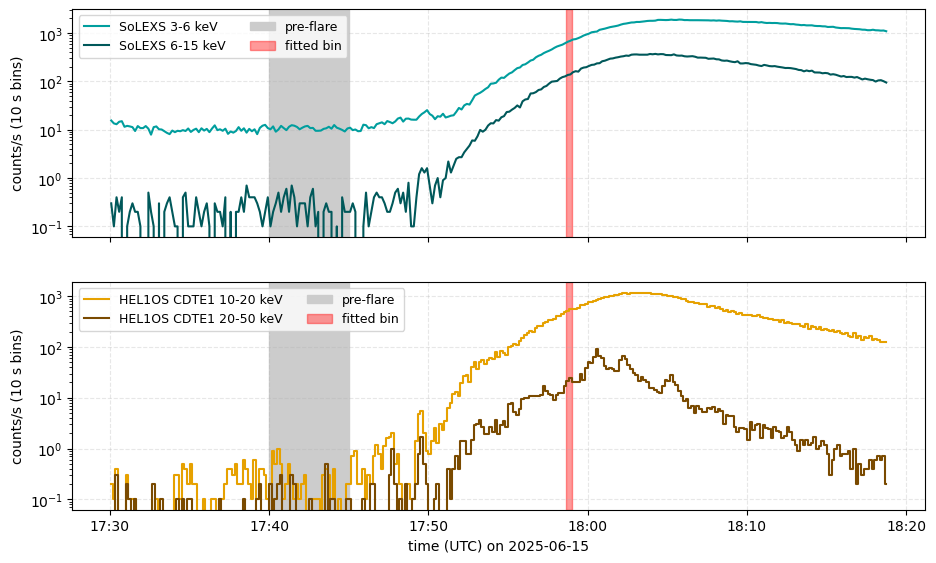

In [3]:
def to_datetime(t):
    return np.datetime64('1970-01-01') + (np.asarray(t) * 1e3).astype('timedelta64[ms]')

STEP = 10                                                    # s
t_edges = np.arange(unix(BKG[0]) - 600, unix(BIN[1]) + 1200, STEP)
t_mid = to_datetime(t_edges[:-1] + STEP / 2)

fig, axs = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)

m = slx_ok & (slx_t >= t_edges[0]) & (slx_t < t_edges[-1])
expo = np.histogram(slx_t[m], t_edges, weights=slx_expo[m])[0]
for lo, hi, col in ((3, 6, '#009e9e'), (6, 15, '#00585a')):
    ch = (slx_eb[:, 0] >= lo) & (slx_eb[:, 1] <= hi)
    n = np.histogram(slx_t[m], t_edges, weights=slx_counts[m][:, ch].sum(axis=1))[0]
    axs[0].plot(t_mid, n / np.maximum(expo, 1e-9), color=col, label=f'SoLEXS {lo}-{hi} keV')

for lo, hi, col in ((10, 20, '#e6a100'), (20, 50, '#7a4a00')):
    sel = (hls_e >= lo) & (hls_e < hi)
    n = np.histogram(hls_t[sel], t_edges)[0]
    axs[1].step(t_mid, n / STEP, where='mid', color=col, label=f'HEL1OS {HLS_DETECTOR} {lo}-{hi} keV')

for ax in axs:
    ax.axvspan(to_datetime(unix(BKG[0])), to_datetime(unix(BKG[1])), color='0.8', label='pre-flare')
    ax.axvspan(to_datetime(unix(BIN[0])), to_datetime(unix(BIN[1])), color='red', alpha=0.4, label='fitted bin')
    ax.set_yscale('log')
    ax.set_ylabel(f'counts/s ({STEP} s bins)')
    ax.legend(loc='upper left', fontsize=9, ncol=2)
    ax.grid(ls='--', alpha=0.3)
axs[1].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
axs[1].set_xlabel(f'time (UTC) on {DAY}')
plt.show()

## 4. Load the spectra and set the energy range
The grouped spectra of notebook 1 (≥ 20 counts per group). The fit range starts where notebook 1 starts it
(SoLEXS 2.8 keV, HEL1OS 10 keV) and ends where the data become too weak:
* **SoLEXS:** first group below `SLX_RATE_MIN` or wider than `SLX_WIDTH_MAX`
* **HEL1OS:** first group with pre-flare-subtracted counts below `HLS_SNR_MIN` σ

In [4]:
def groups(name):
    # good groups (quality 0) of a grouped spectrum, as (first, last + 1) channel index
    d = fits.getdata(SPEC / name, 1)
    g, q = np.asarray(d['GROUPING']), np.asarray(d['QUALITY'])
    out = []
    for a in np.flatnonzero((g == 1) & (q == 0)):
        b = a + 1
        while b < len(g) and g[b] == -1 and q[b] == 0:
            b += 1
        out.append((a, b))
    return out

def counts(name):
    with fits.open(SPEC / name) as h:
        return np.asarray(h[1].data['COUNTS'], float), float(h[1].header['EXPOSURE'])

# ---- SoLEXS: keep groups from the first one up, until the rate or width limit
s_c, s_exp = counts(SLX_FILE)
s_all = groups(SLX_FILE)
s_groups = []
for a, b in s_all:
    width = slx_eb[b - 1, 1] - slx_eb[a, 0]
    if s_c[a:b].sum() / s_exp / width < SLX_RATE_MIN or width > SLX_WIDTH_MAX:
        break
    s_groups.append((a, b))

# ---- HEL1OS: keep groups until the pre-flare-subtracted counts drop below HLS_SNR_MIN sigma
h_c, h_exp = counts(HLS_FILE)
h_bc, h_bexp = counts(HLS_BKG_FILE)
scale = h_exp / h_bexp                              # pre-flare counts scaled to the bin length
h_all = groups(HLS_FILE)
h_groups = []
for a, b in h_all:
    S, B = h_c[a:b].sum(), h_bc[a:b].sum() * scale
    if S - B < HLS_SNR_MIN * np.sqrt(S + B * scale):
        break
    h_groups.append((a, b))

def load_bin():
    # SoLEXS = data group 1, HEL1OS = data group 2, only the kept groups noticed
    load(f'1:1 {SLX_FILE} 2:2 {HLS_FILE}')
    for i, eb_, all_, kept in ((1, slx_eb, s_all, s_groups), (2, hls_eb, h_all, h_groups)):
        if len(kept) < len(all_):                   # ignore from the middle of the first group not kept
            a, b = all_[len(kept)]
            xs.AllData(i).ignore(f'{(eb_[a, 0] + eb_[b - 1, 1]) / 2:.4f}-**')

load_bin()
slx_range = (slx_eb[s_groups[0][0], 0], slx_eb[s_groups[-1][1] - 1, 1])
hls_range = (hls_eb[h_groups[0][0], 0], hls_eb[h_groups[-1][1] - 1, 1])
print(f'SoLEXS: {s_c.sum():7.0f} counts in {s_exp:4.1f} s | fitted {slx_range[0]:.2f}-{slx_range[1]:.2f} keV, '
      f'{len(xs.AllData(1).noticed)} groups')
print(f'HEL1OS: {h_c.sum():7.0f} counts in {h_exp:4.1f} s | fitted {hls_range[0]:.2f}-{hls_range[1]:.2f} keV, '
      f'{len(xs.AllData(2).noticed)} groups (pre-flare: {h_bc.sum():.0f} counts in {h_bexp:.0f} s)')

SoLEXS:   51112 counts in 20.0 s | fitted 2.79-11.13 keV, 115 groups
HEL1OS:   22989 counts in 20.0 s | fitted 10.04-46.23 keV, 76 groups (pre-flare: 296 counts in 300 s)


## 5. SoLEXS pre-flare fit
`chisoth` fit of the pre-flare spectrum (*T* and *EM* free). The result is frozen in the joint fit.

pre-flare: T0 = 8.37 MK, EM0 = 0.0679e49 cm^-3, chi2 = 89.4 / 48 = 1.86


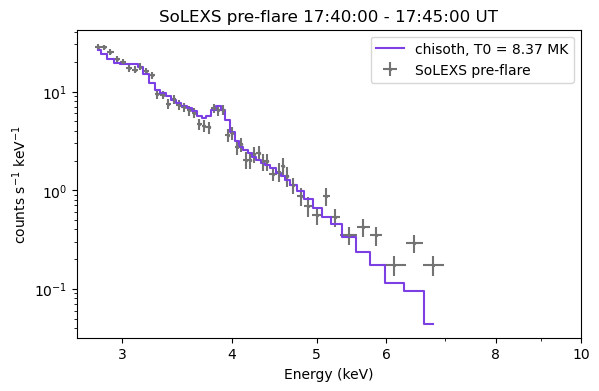

In [5]:
xs.AllModels.clear()
load(f'1:1 {SLX_PRE_FILE}')
mp = xs.Model('chisoth')
xs.AllModels.systematic = SYSTEMATIC
for name in mp.chisoth.parameterNames:
    getattr(mp.chisoth, name).frozen = True
mp.chisoth.logT.frozen = mp.chisoth.norm.frozen = False

best = None
for logT in (6.3, 6.5, 6.7, 6.9, 7.1):
    mp.chisoth.logT.values = [logT, 0.01, 6.0, 6.0, 7.7, 7.7]
    mp.chisoth.norm.values = [10, 0.01, 0, 0, 1e20, 1e24]
    fit()
    if best is None or xs.Fit.statistic < best[0]:
        best = (xs.Fit.statistic, mp.chisoth.logT.values[0], mp.chisoth.norm.values[0])
mp.chisoth.logT.values = best[1]
mp.chisoth.norm.values = best[2]
fit()
PRE_LOGT, PRE_NORM = mp.chisoth.logT.values[0], mp.chisoth.norm.values[0]
print(f'pre-flare: T0 = {10**(PRE_LOGT-6):.2f} MK, EM0 = {PRE_NORM/1000:.4f}e49 cm^-3, '
      f'chi2 = {xs.Fit.statistic:.1f} / {xs.Fit.dof} = {xs.Fit.statistic/xs.Fit.dof:.2f}')

# quick look
xs.Plot('ldata')
x, xe, y, ye, mo = (np.array(f()) for f in (xs.Plot.x, xs.Plot.xErr, xs.Plot.y, xs.Plot.yErr, xs.Plot.model))
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.errorbar(x, y, ye, xe, fmt='.', ms=3, color='0.45', label='SoLEXS pre-flare')
ax.step(x, mo, where='mid', color='#7b3fe4', label=f'chisoth, T0 = {10**(PRE_LOGT-6):.2f} MK')
ax.set(xscale='log', yscale='log', xlabel='Energy (keV)', ylabel='counts s$^{-1}$ keV$^{-1}$',
       title=f'SoLEXS pre-flare {BKG[0]} - {BKG[1]} UT')
ax.set_xticks([3, 4, 5, 6, 8, 10])
ax.set_xticklabels(['3', '4', '5', '6', '8', '10'])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.legend()
plt.show()

## 6. Joint fit
SoLEXS = data group 1, HEL1OS = data group 2, 5 % systematic error.

1. **Start values:** flare `chisoth` alone, from a few temperatures
2. **Final fit:** `bknpower` added, started from several (&gamma;, *E*<sub>b</sub>); the best fit is kept

In [6]:
xs.AllModels.clear()
load_bin()

m = xs.Model('constant*(chisoth + bknpower + chisoth)')
xs.AllModels.systematic = SYSTEMATIC
th, pl, pre = m.chisoth, m.bknpower, getattr(m, m.componentNames[-1])   # flare, non-thermal, pre-flare
C_slx = m.constant.factor                           # constant of SoLEXS (group 1)
C_hls = xs.AllModels(2).constant.factor             # constant of HEL1OS (group 2)
C_slx.values = 1.0
C_slx.frozen = True
C_hls.untie()
C_hls.frozen = False

# pre-flare chisoth: frozen at the step-5 values for SoLEXS, zero for HEL1OS (its pre-flare is subtracted)
for name in pre.parameterNames:
    getattr(pre, name).frozen = True
pre.logT.values = PRE_LOGT
pre.norm.values = PRE_NORM
pre_hls = xs.AllModels(2)(pre.norm.index)
pre_hls.untie()
pre_hls.values = 0.0
pre_hls.frozen = True

# flare chisoth: everything frozen except log T and EM (norm, in 1e46 cm^-3); Ni tied to Fe (default Ni/Fe ratio)
for name in th.parameterNames:
    getattr(th, name).frozen = True
th.Ni.link = f'p{th.Fe.index} - {th.Fe.values[0] - th.Ni.values[0]:.4f}'
th.logT.values = [7.2, 0.01, 6.0, 6.0, 7.7, 7.7]
th.norm.values = [1000, 0.01, 0, 0, 1e20, 1e24]
th.logT.frozen = th.norm.frozen = False

# bknpower: off for step 1 (norm = 0, all frozen)
for name in pl.parameterNames:
    getattr(pl, name).frozen = True
pl.PhoIndx1.values = 1.5
pl.norm.values = 0.0

def free_params():
    return [p for p in [m(i) for i in range(1, m.nParameters + 1)] + [C_hls] if not p.frozen and not p.link]

def snapshot():
    return {('C' if p is C_hls else p.index): p.values[0] for p in free_params()}

def restore(snap):
    for k, v in snap.items():
        (C_hls if k == 'C' else m(k)).values = v

# ---- step 1: start values (flare chisoth only)
best = None
for logT in (6.9, 7.05, 7.2, 7.35):
    th.logT.values = logT
    th.norm.values = 1000
    C_hls.values = 1.0
    fit()
    if best is None or xs.Fit.statistic < best[0]:
        best = (xs.Fit.statistic, snapshot())
restore(best[1])
for el in ('Ar', 'Ca', 'Fe'):
    getattr(th, el).frozen = False
fit()
start = snapshot()
print(f'start values: T = {10**(th.logT.values[0]-6):.2f} MK, EM = {th.norm.values[0]/1000:.3f}e49 cm^-3')

# ---- step 2: thermal + bknpower
# rough start value of the bknpower norm: half of the HEL1OS photon flux at ~21 keV is non-thermal
sel = (hls_eb[:, 0] >= 18) & (hls_eb[:, 1] <= 24)
net = h_c[sel].sum() - h_bc[sel].sum() * scale
arf = fits.getdata(HLS_ARF, 1)
area21 = np.interp(21.0, (arf['ENERG_LO'] + arf['ENERG_HI']) / 2, arf['SPECRESP'])   # cm^2
flux21 = max(net, 5.0) / (h_exp * area21 * 6.0)                                      # photons/cm^2/s/keV
def norm_start(gamma, ebreak):
    return float(0.5 * flux21 * 21.0**gamma / ebreak**(gamma - 1.5))

EB_MIN = 12.0                                       # keV, lowest break: 2 keV above the HEL1OS range start
best = None
for gamma, ebreak in ((5, 13), (4, 12), (6, 13), (8, 14)):
    restore(start)
    pl.BreakE.values = [max(ebreak, EB_MIN), 0.1, EB_MIN, EB_MIN, 30, 30]
    pl.PhoIndx2.values = [gamma, 0.05, 2, 2, 10, 10]
    pl.norm.values = [norm_start(gamma, ebreak), 0.01, 0, 0, 1e20, 1e24]
    pl.BreakE.frozen = pl.PhoIndx2.frozen = pl.norm.frozen = False
    fit()
    print(f'  start gamma = {gamma}, Eb = {ebreak} -> gamma = {pl.PhoIndx2.values[0]:.2f}, '
          f'Eb = {pl.BreakE.values[0]:.2f} keV, chi2 = {xs.Fit.statistic:.1f}')
    if best is None or xs.Fit.statistic < best[0]:
        best = (xs.Fit.statistic, snapshot())
restore(best[1])
fit()
print(f'best fit: chi2 = {xs.Fit.statistic:.1f} / {xs.Fit.dof} = {xs.Fit.statistic/xs.Fit.dof:.2f}')

start values: T = 26.59 MK, EM = 0.390e49 cm^-3
  start gamma = 5, Eb = 13 -> gamma = 5.59, Eb = 13.30 keV, chi2 = 230.2


  start gamma = 4, Eb = 12 -> gamma = 5.59, Eb = 13.29 keV, chi2 = 230.2
  start gamma = 6, Eb = 13 -> gamma = 5.59, Eb = 13.29 keV, chi2 = 230.2
  start gamma = 8, Eb = 14 -> gamma = 5.59, Eb = 13.28 keV, chi2 = 230.2
best fit: chi2 = 230.2 / 182 = 1.26


## 7. Errors (MCMC)
68 % ranges of *T*, *EM*, &gamma;, *E*<sub>b</sub> and *C*: an MCMC chain is run from the best fit (Goodman-Weare,
16 walkers, 16000 steps, 1600 burn-in, fixed random seed), then XSPEC's `error` command reads the ranges from the chain.

The best fit can lie near one edge of its range when the chain's distribution is lopsided.

In [7]:
chain = OUT / f'chain_{tag}.fits'
chain.unlink(missing_ok=True)
xs.AllChains.clear()
xs.Xset.seed = 2025                                 # fixed random seed: the same result every run
try:
    xs.Chain(str(chain), burn=1600, runLength=16000, rand=True, algorithm='gw', walkers=16)
except Exception:
    # fit covariance not usable (e.g. a parameter at a limit): start the walkers from the parameter step sizes
    xs.AllChains.clear()
    chain.unlink(missing_ok=True)
    xs.AllChains.defProposal = 'gaussian deltas 10'
    xs.Chain(str(chain), burn=1600, runLength=16000, rand=True, algorithm='gw', walkers=16)
    xs.AllChains.defProposal = 'gaussian fit'

# errors from the loaded chain (the HEL1OS constant is parameter 1 of data group 2 = number m.nParameters + 1)
pars = {'logT': th.logT, 'EM': th.norm, 'gamma': pl.PhoIndx2, 'Eb': pl.BreakE, 'C': C_hls}
number = {k: (m.nParameters + 1 if p is C_hls else p.index) for k, p in pars.items()}
xs.Fit.error('maximum 1000 1.0 ' + ' '.join(str(i) for i in number.values()))
res = {k: (p.values[0], p.error[0], p.error[1]) for k, p in pars.items()}   # (best fit, lower, upper)
xs.AllChains.clear()
print('done, chain saved as', chain.name)

done, chain saved as chain_175840-175900.fits


## 8. Results
**Left:** count spectrum and residuals. **Right:** unfolded photon spectrum.
Black: total model, violet: flare `chisoth`, red: `bknpower`, gray: pre-flare spectrum.

* In the count spectrum each component appears twice (SoLEXS and HEL1OS), at different heights, because each
  instrument's model is drawn through its own response.
* The unfolded spectrum shows the photon model: one broken power law with its break at *E*<sub>b</sub>.

bin 17:58:40 - 17:59:00 UT
  T     =  20.30  (19.90 - 20.54) MK
  EM    =  0.568  (0.556 - 0.588) x 1e49 cm^-3
  Ar, Ca, Fe = 6.42, 6.69, 7.77  (log A, H = 12)
  gamma =   5.59  (5.46 - 5.75)
  Eb    =  13.28  (12.75 - 13.87) keV
  C     =  0.890  (0.843 - 0.947)  (HEL1OS / SoLEXS)
  chi2  = 230.2 / 182 = 1.26
  pre-flare (frozen, SoLEXS only): T0 = 8.37 MK, EM0 = 0.0679e49 cm^-3


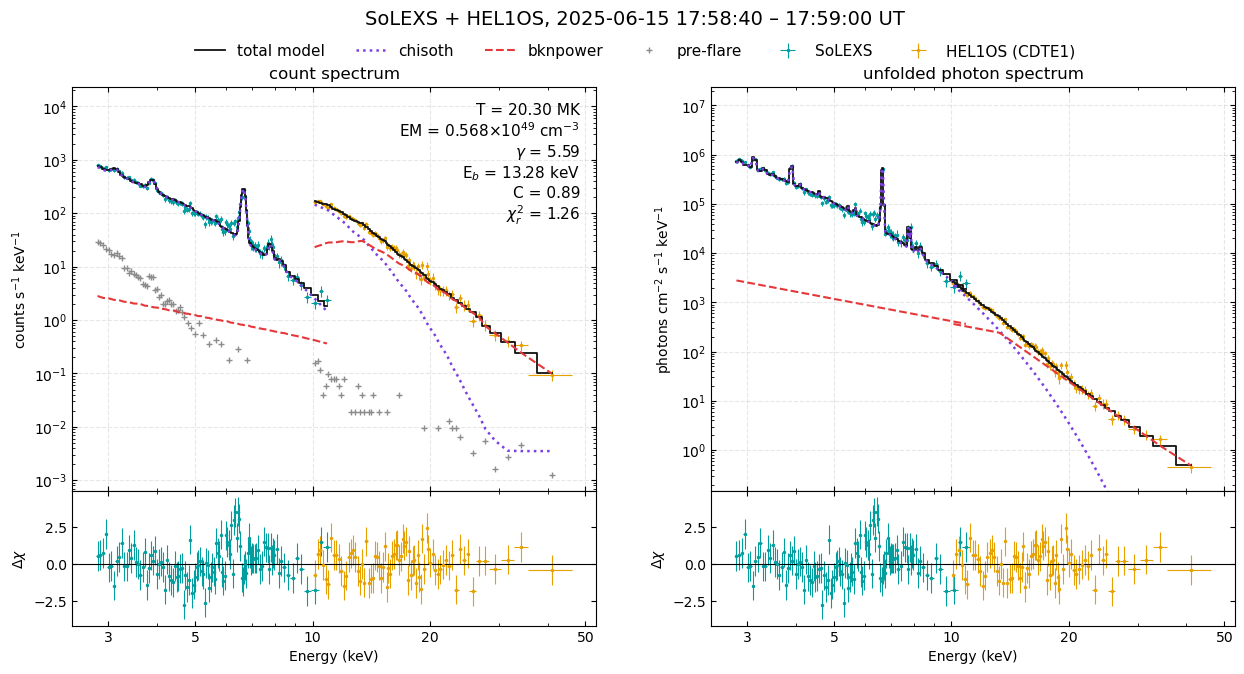

saved: outputs/joint_fit/fit_175840-175900.png and fit_175840-175900.xcm


In [8]:
COL = {'SoLEXS': '#009e9e', 'HEL1OS': '#e6a100'}
C_TOT, C_TH, C_NT, C_BKG = '#111111', '#7b3fe4', '#e5383b', '0.55'

# ---- numbers
T, T_lo, T_hi = (10**(x - 6) for x in res['logT'])
EM, EM_lo, EM_hi = (x / 1000 for x in res['EM'])
chi2, dof = xs.Fit.statistic, xs.Fit.dof
print(f'bin {BIN[0]} - {BIN[1]} UT')
print(f'  T     = {T:6.2f}  ({T_lo:.2f} - {T_hi:.2f}) MK')
print(f'  EM    = {EM:6.3f}  ({EM_lo:.3f} - {EM_hi:.3f}) x 1e49 cm^-3')
print(f'  Ar, Ca, Fe = {th.Ar.values[0]:.2f}, {th.Ca.values[0]:.2f}, {th.Fe.values[0]:.2f}  (log A, H = 12)')
for k in ('gamma', 'Eb'):
    v, lo, hi = res[k]
    print(f'  {k:5s} = {v:6.2f}  ({lo:.2f} - {hi:.2f})' + (' keV' if k == 'Eb' else ''))
print(f'  C     = {res["C"][0]:6.3f}  ({res["C"][1]:.3f} - {res["C"][2]:.3f})  (HEL1OS / SoLEXS)')
print(f'  chi2  = {chi2:.1f} / {dof} = {chi2/dof:.2f}')
print(f'  pre-flare (frozen, SoLEXS only): T0 = {10**(PRE_LOGT-6):.2f} MK, EM0 = {PRE_NORM/1000:.4f}e49 cm^-3')

# ---- arrays from XSPEC (components: 1 = flare chisoth, 2 = bknpower, 3 = pre-flare chisoth)
xs.Plot.add = True
xs.Plot.background = True
xs.Plot('ldata')
P = {}
for g, inst in ((1, 'SoLEXS'), (2, 'HEL1OS')):
    P[inst] = dict(x=np.array(xs.Plot.x(g)), xe=np.array(xs.Plot.xErr(g)), y=np.array(xs.Plot.y(g)),
                   ye=np.array(xs.Plot.yErr(g)), model=np.array(xs.Plot.model(g)),
                   comps=[np.array(xs.Plot.addComp(k, g)) for k in (1, 2)])
hls_bkg = np.array(xs.Plot.backgroundVals(2))       # HEL1OS pre-flare (subtracted), on the fitted groups
xs.Plot('delchi')
for g, inst in ((1, 'SoLEXS'), (2, 'HEL1OS')):
    P[inst]['delchi'] = np.array(xs.Plot.y(g))
xs.Plot('ufspec')
for g, inst in ((1, 'SoLEXS'), (2, 'HEL1OS')):
    P[inst]['uf'] = dict(y=np.array(xs.Plot.y(g)), ye=np.array(xs.Plot.yErr(g)), model=np.array(xs.Plot.model(g)),
                         comps=[np.array(xs.Plot.addComp(k, g)) for k in (1, 2)])
xs.Plot.background = False

# SoLEXS pre-flare spectrum (counts/s/keV per group)
s_bc, s_bexp = counts(SLX_PRE_FILE)
s_bgroups = groups(SLX_PRE_FILE)
pre_x = np.array([(slx_eb[a, 0] + slx_eb[b - 1, 1]) / 2 for a, b in s_bgroups])
pre_y = np.array([s_bc[a:b].sum() / s_bexp / (slx_eb[b - 1, 1] - slx_eb[a, 0]) for a, b in s_bgroups])

# ---- figure
fig = plt.figure(figsize=(15, 7))
gs = fig.add_gridspec(2, 2, height_ratios=[3, 1], hspace=0, wspace=0.22)
for col, unfolded in ((0, False), (1, True)):
    ax = fig.add_subplot(gs[0, col])
    rax = fig.add_subplot(gs[1, col], sharex=ax)
    for inst, d in P.items():
        q = d['uf'] if unfolded else d
        first = inst == 'SoLEXS'
        label = 'SoLEXS' if first else f'HEL1OS ({HLS_DETECTOR})'
        ax.errorbar(d['x'], q['y'], q['ye'], d['xe'], fmt='.', ms=3, lw=0.8, color=COL[inst], label=label, zorder=2)
        ax.step(d['x'], q['model'], where='mid', color=C_TOT, lw=1.3, label='total model' if first else None, zorder=3)
        ax.plot(d['x'], q['comps'][0], ':', color=C_TH, lw=1.8, label='chisoth' if first else None, zorder=3)
        ax.plot(d['x'], q['comps'][1], '--', color=C_NT, lw=1.5, label='bknpower' if first else None, zorder=3)
        rax.errorbar(d['x'], d['delchi'], 1.0, d['xe'], fmt='.', ms=3, lw=0.8, color=COL[inst])
    if not unfolded:
        ok = hls_bkg > 0
        ax.plot(pre_x, pre_y, '+', color=C_BKG, ms=4, label='pre-flare', zorder=1)
        ax.plot(P['HEL1OS']['x'][ok], hls_bkg[ok], '+', color=C_BKG, ms=4, zorder=1)
    ys = [P[i]['uf']['y'] if unfolded else P[i]['y'] for i in P]
    ymax = max(np.nanmax(y) for y in ys)
    ymin = np.nanmin(ys[1][ys[1] > 0]) / 3
    if not unfolded:                                # make room for the pre-flare points
        ymin = min(ymin, pre_y[pre_y > 0].min() / 2, hls_bkg[hls_bkg > 0].min() / 2)
    ax.set(xscale='log', yscale='log', ylim=(max(ymin, ymax * 1e-8), ymax * 30))
    ax.set_ylabel('photons cm$^{-2}$ s$^{-1}$ keV$^{-1}$' if unfolded else 'counts s$^{-1}$ keV$^{-1}$')
    ax.set_title('unfolded photon spectrum' if unfolded else 'count spectrum', fontsize=12)
    ax.tick_params(labelbottom=False, which='both', direction='in', top=True, right=True)
    ax.grid(ls='--', alpha=0.3)
    rax.axhline(0, color='k', lw=0.8)
    rax.set(xscale='log', xlabel='Energy (keV)', ylabel=r'$\Delta\chi$')
    rax.tick_params(which='both', direction='in', top=True, right=True)
    rax.set_xticks([3, 5, 10, 20, 50])
    rax.set_xticklabels(['3', '5', '10', '20', '50'])
    if col == 0:
        fig.legend(*ax.get_legend_handles_labels(), loc='lower center', bbox_to_anchor=(0.5, 0.9), ncol=6,
                   frameon=False, fontsize=11)
        txt = [f'T = {T:.2f} MK', f'EM = {EM:.3f}$\\times10^{{49}}$ cm$^{{-3}}$',
               f'$\\gamma$ = {res["gamma"][0]:.2f}', f'E$_b$ = {res["Eb"][0]:.2f} keV',
               f'C = {res["C"][0]:.2f}', f'$\\chi^2_r$ = {chi2/dof:.2f}']
        ax.text(0.97, 0.96, '\n'.join(txt), transform=ax.transAxes, ha='right', va='top', fontsize=11)
fig.suptitle(f'SoLEXS + HEL1OS, {DAY} {BIN[0]} – {BIN[1]} UT', fontsize=14, y=0.99)
fig.savefig(OUT / f'fit_{tag}.png', dpi=130, bbox_inches='tight')
plt.show()

# ---- save the XSPEC session (reload in XSPEC with: @fit_<bin>.xcm)
xcm = OUT / f'fit_{tag}.xcm'
xcm.unlink(missing_ok=True)
xs.Xset.save(str(xcm), info='a')
print('saved:', (OUT / f'fit_{tag}.png').relative_to(ROOT), 'and', xcm.name)